# SS3 Part B — Applying the final model to STADIOEquities' client data

**Project:** Predicting STADIOEquities account activation (CAP182 capstone)
**Final method carried forward from SS2:** Random Forest (Model 2), recommended in the Part D report because its higher precision means more of the accounts it flags are genuinely worth a nudge. Logistic Regression (Model 1) is kept as the interpretable benchmark.

SS2 proved the approach on the public UCI Bank Marketing data. This notebook applies the same method to the four extracts STADIOEquities supplied, and also carries out the improvements Part D listed: hyperparameter tuning, probability calibration, an out-of-time split, re-engineered behavioural features, and re-tuned class-imbalance handling.


In [3]:
# Setup: libraries, paths, plotting style
import json, pickle, re, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss,
                             classification_report, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

SEED = 42
ROOT = Path.cwd()
RAW = ROOT / "Data" / "raw" / "client"
PROCESSED = ROOT / "Data" / "processed"
MODELS = ROOT / "models"
METRICS = ROOT / "results" / "metrics"
FIGS = ROOT / "results" / "reports" / "ss3_figures"
for p in (PROCESSED, MODELS, METRICS, FIGS):
    p.mkdir(parents=True, exist_ok=True)

# Colour roles (colour-blind-safe, validated categorical palette)
C_TRAIN, C_TEST, C_VAL = "#2a78d6", "#eb6834", "#1baf7a"
C_GREY, C_INK, C_MUTED = "#8c8b86", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c2", "axes.labelcolor": C_MUTED,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": C_INK,
    "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.8,
    "xtick.color": C_MUTED, "ytick.color": C_MUTED, "lines.linewidth": 2,
    "legend.frameon": False, "font.size": 10,
})
def save(fig, name):
    fig.savefig(FIGS / f"{name}.png")

---
<div style="background:#2a78d6;color:white;padding:10px 14px;border-radius:6px"><b>COMPONENT 1 — DATASET LOADING</b></div>

# 1. Dataset loading

The four client extracts are stored unmodified in `Data/raw/client/`. They are read as text first (`dtype=str`) so nothing is silently coerced before the data-quality checks in Section 2 — the client's README warns that dates, casing and numbers are not clean.

In [4]:
# 1.1 Load the four raw extracts exactly as received
FILES = {
    "account":      "1_account_registration.csv",
    "behavioural":  "2_app_web_behavioural.csv",
    "demographics": "3_client_demographics.csv",
    "marketing":    "4_marketing_acquisition.csv",
}
raw = {k: pd.read_csv(RAW / f, dtype=str, keep_default_na=False) for k, f in FILES.items()}

summary = pd.DataFrame({
    "file": FILES.values(),
    "rows": [len(d) for d in raw.values()],
    "columns": [d.shape[1] for d in raw.values()],
    "unique account_id": [d["account_id"].nunique() for d in raw.values()],
    "exact duplicate rows": [int(d.duplicated().sum()) for d in raw.values()],
}, index=FILES.keys())
summary

,file,rows,columns,unique account_id,exact duplicate rows
account,1_account_registration.csv,5433,12,5417,16
behavioural,2_app_web_behavioural.csv,42644,9,3599,0
demographics,3_client_demographics.csv,5417,4,5417,0
marketing,4_marketing_acquisition.csv,3599,6,3599,0


In [5]:
# 1.2 Peek at each table
for name, df in raw.items():
    print(f"--- {name} ---")
    display(df.head(3))

--- account ---


,account_id,registration_date,registration_channel,kyc_status,kyc_completion_date,ever_funded_flag,first_deposit_date,first_deposit_amount,current_balance,active_in_last_90_days_flag,client_province,extract_date
0,acc_00019000,2021-02-15 08:34:15,Paid social,Rejected,,FALSE,,,0,FALSE,GP,2026-09-01
1,acc_00019001,2021-05-12 17:24:25,Referral,Completed,2021-05-13 00:57:20,TRUE,2021-05-14 22:24:42,130050,573612,FALSE,EC,2026-09-01
2,acc_00019002,2020-12-31 01:39:16,Paid social,Completed,2020-12-31 23:12:20,FALSE,,,0,FALSE,EC,2026-09-01


--- behavioural ---


,account_id,session_id,event_timestamp,platform,screen_step_name,onboarding_step_number,time_on_step,step_outcome,session_duration
0,acc_00019416,sess_0091552,2023-04-10 10:31:17,Web,Support,,73,Advanced,218
1,acc_00023196,sess_0121242,2025-05-09 18:17:48,App,Onboarding_Step2_CONTACT,2,30,Advanced,229
2,acc_00019397,sess_0091355,2026-04-13 00:46:13,App,Watchlist,,45,Advanced,243


--- demographics ---


,account_id,age_at_sign_up,stated_risk_appetite,stated_investment_goal
0,acc_00019000,29,Low,Long-term growth
1,acc_00019001,26,High,Saving for a goal
2,acc_00019002,38,Medium,Long-term growth


--- marketing ---


,account_id,acquisition_channel,campaign_name,acquisition_cost,onboarding_nudge_sent_count,last_nudge_engagement
0,acc_00019003,Organic search,,2574,8,Clicked
1,acc_00019004,App store,Q3_Payday_2024,10989,5,No engagement
2,acc_00019005,Paid search,Q2_TaxFree_2024,13928,0,No engagement


In [6]:
# 1.3 The outcome label as delivered: ever_funded_flag
acc = raw["account"].drop_duplicates()
label_counts = acc["ever_funded_flag"].value_counts()
print("Unique accounts:", len(acc))
print(label_counts.to_string())
print(f"Funded share: {label_counts['TRUE'] / len(acc):.1%}  |  "
      f"imbalance (not funded : funded) = {label_counts['FALSE'] / label_counts['TRUE']:.2f} : 1")

Unique accounts: 5417
ever_funded_flag
FALSE    3188
TRUE     2229
Funded share: 41.1%  |  imbalance (not funded : funded) = 1.43 : 1


### Dataset summary

| Extract | Rows | What one row is | Used for |
|---|---|---|---|
| `1_account_registration.csv` | 5,433 (5,417 unique accounts + 16 exact duplicates) | One account | Registration date, channel, province, KYC timing, **the label** |
| `2_app_web_behavioural.csv` | 42,644 events from 3,599 accounts | One screen / onboarding-step event | First-48-hour behaviour features |
| `3_client_demographics.csv` | 5,417 | One account at sign-up | Age, risk appetite, investment goal |
| `4_marketing_acquisition.csv` | 3,599 | One account | Campaign and acquisition cost |

**Classes.** This is a binary classification problem. The client's label `ever_funded_flag` splits the 5,417 unique accounts into **funded (2,229 accounts, 41.1%)** and **never funded (3,188 accounts, 58.9%)** — an imbalance of about **1.43 : 1** in favour of the negative class. Note that the business brief says 41% of accounts have *never* deposited; in this extract it is the other way round (41% *have* funded). That discrepancy is flagged for the client rather than "corrected".

The label used for modelling is refined in Section 2 so that it only counts activation that happens **after** the point at which the model would score an account. On that modelling cohort the positive class is smaller (**824 of 2,863 accounts, 28.8%; about 2.5 : 1**), which is why class imbalance is still handled in training.

**Not every column is ours to use.** The extracts carry fields for other analyses (dormancy, balances) — Section 2.2 lists what is kept, what is dropped and why.

---
<div style="background:#2a78d6;color:white;padding:10px 14px;border-radius:6px"><b>COMPONENT 2 — DATASET PREPROCESSING</b></div>

# 2. Dataset preprocessing

Steps, in order:

1. **Clean** each table (duplicates, mixed date formats, inconsistent casing, implausible values).
2. **Choose the fields this project needs** and drop leakage.
3. **Define the scoring checkpoint and the label** — what the model is allowed to know, and what it predicts.
4. **Engineer features** from the first 48 hours of behaviour, plus static account information.
5. **Split chronologically** into training, validation and test sets.

The reasons for each choice are explained in the markdown block at the end of this section (2.6).

In [7]:
# 2.1a Account table: duplicates and mixed date formats
acc = raw["account"].drop_duplicates().copy()
assert acc["account_id"].is_unique
print("Exact duplicate account rows removed:", len(raw["account"]) - len(acc))

ISO = r"^\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}$"
odd = acc.loc[~acc["registration_date"].str.match(ISO), "registration_date"]
print(f"registration_date values not in yyyy-MM-dd hh:mm:ss: {len(odd)}")
print("Examples:", odd.head(8).tolist())

Exact duplicate account rows removed: 16
registration_date values not in yyyy-MM-dd hh:mm:ss: 55
Examples: ['25/11/2023', '2026/08/10', '04/03/2022 16:35', '12/05/2026', '11/28/2025 10:48', '2025/03/20', '08/31/2022 08:33', '08/19/2023 17:26']


The 55 non-standard registration dates come in three shapes. To decide day/month order, each was checked against the same account's KYC-completion date and first behavioural event (which are clean). Every case is consistent with one rule:

| Shape | Example | Read as |
|---|---|---|
| `yyyy/MM/dd` | `2025/03/20` | year / month / day |
| `dd/MM/yyyy` (no time) | `12/05/2026` → KYC on 2026-05-14 | **day / month** / year |
| `MM/dd/yyyy hh:mm` (with time) | `11/28/2025 10:48` | **month / day** / year (US style) |

A generic parser gets this wrong — it read `12/05/2026` as 5 December 2026, *after* the extract date. The parser below applies the rule explicitly and then checks that no date falls after the extract or after the account's own KYC / deposit.

In [8]:
# 2.1b Parse dates with the explicit rule, then sanity-check them
def parse_registration(s: str) -> pd.Timestamp:
    if re.match(ISO, s):                         return pd.to_datetime(s, format="%Y-%m-%d %H:%M:%S")
    if re.match(r"^\d{4}/\d{2}/\d{2}$", s):      return pd.to_datetime(s, format="%Y/%m/%d")
    if re.match(r"^\d{2}/\d{2}/\d{4} \d", s):    return pd.to_datetime(s, format="%m/%d/%Y %H:%M")
    if re.match(r"^\d{2}/\d{2}/\d{4}$", s):      return pd.to_datetime(s, format="%d/%m/%Y")
    raise ValueError(f"Unrecognised date: {s!r}")

acc["registration_date"] = acc["registration_date"].map(parse_registration)
for c in ["kyc_completion_date", "first_deposit_date"]:
    acc[c] = pd.to_datetime(acc[c].replace("", None), format="%Y-%m-%d %H:%M:%S")
acc["extract_date"] = pd.to_datetime(acc["extract_date"])
EXTRACT = acc["extract_date"].max()

checks = {
    "registered after extract date": (acc["registration_date"] > EXTRACT).sum(),
    "KYC before registration": (acc["kyc_completion_date"] < acc["registration_date"]).sum(),
    "deposit before registration": (acc["first_deposit_date"] < acc["registration_date"]).sum(),
}
print(checks)
assert sum(checks.values()) == 0
print("Registration range:", acc["registration_date"].min(), "→", acc["registration_date"].max())

{'registered after extract date': np.int64(0), 'KYC before registration': np.int64(0), 'deposit before registration': np.int64(0)}
Registration range: 2020-09-01 00:24:14 → 2026-08-14 21:45:12


In [9]:
# 2.1c Categorical clean-up, label consistency and the other tables
acc["client_province"] = acc["client_province"].str.strip().str.upper()
print("Provinces after clean-up:", sorted(acc["client_province"].unique()))

acc["ever_funded"] = (acc["ever_funded_flag"] == "TRUE").astype(int)
print("Funded flag without a deposit date:", ((acc["ever_funded"] == 1) & acc["first_deposit_date"].isna()).sum(),
      "| deposit date without funded flag:", ((acc["ever_funded"] == 0) & acc["first_deposit_date"].notna()).sum())

beh = raw["behavioural"].copy()
beh["event_timestamp"] = pd.to_datetime(beh["event_timestamp"], format="%Y-%m-%d %H:%M:%S")
beh["onboarding_step_number"] = pd.to_numeric(beh["onboarding_step_number"])
for c in ["time_on_step", "session_duration"]:
    beh[c] = pd.to_numeric(beh[c])

demo = raw["demographics"].copy()
demo["age_at_sign_up"] = pd.to_numeric(demo["age_at_sign_up"].replace("", None))
implausible_age = demo["age_at_sign_up"] > 100
print("Implausible ages set to missing:", demo.loc[implausible_age, "age_at_sign_up"].tolist())
demo.loc[implausible_age, "age_at_sign_up"] = np.nan
demo["stated_investment_goal"] = demo["stated_investment_goal"].replace("", "Not stated")

mkt = raw["marketing"].copy()
mkt["acquisition_cost"] = pd.to_numeric(mkt["acquisition_cost"])
mkt["campaign_name"] = mkt["campaign_name"].replace("", "No campaign")

# Claims in the client README, checked
both = acc.merge(mkt, on="account_id")
print(f"\nregistration_channel == acquisition_channel for {(both.registration_channel == both.acquisition_channel).mean():.0%} of accounts "
      "→ the two columns are duplicates; only registration_channel is kept.")
print(f"Mean acquisition cost: R{mkt.acquisition_cost.mean() / 100:.2f} "
      "(client README says 'close to R180'; the data says otherwise — flagged, not altered).")

Provinces after clean-up: ['EC', 'FS', 'GP', 'KZN', 'LP', 'MP', 'NC', 'NW', 'WC']
Funded flag without a deposit date: 0 | deposit date without funded flag: 0
Implausible ages set to missing: [110.07, 104.62]

registration_channel == acquisition_channel for 100% of accounts → the two columns are duplicates; only registration_channel is kept.
Mean acquisition cost: R148.97 (client README says 'close to R180'; the data says otherwise — flagged, not altered).


### 2.2 Which fields this project uses

The extracts were built for several analyses. Only fields that would be **known when the account is scored** are allowed in.

| Field(s) | Decision | Why |
|---|---|---|
| `first_deposit_date` | Used **only to build the label** | It *is* the outcome event |
| `first_deposit_amount`, `current_balance`, `active_in_last_90_days_flag` | **Dropped** | Post-outcome — the client README flags these as leakage. Dormancy is a separate model (out of scope here). |
| `kyc_status` | **Dropped** | A snapshot at the 2026 extract date, so "Abandoned/Completed" is decided long after scoring time. Replaced by *"KYC completed within the first 48 h"*, computed from `kyc_completion_date`. |
| `ever_funded_flag` | Replaced by a time-bounded label | See 2.3 |
| `acquisition_channel` | **Dropped** | Identical to `registration_channel` (checked above) |
| `onboarding_nudge_sent_count`, `last_nudge_engagement` | **Dropped** | Lifetime totals with no timestamp, so they can't be cut at the checkpoint. Nudges continue after the scoring point, and the model's purpose is to decide who gets them. |
| `campaign_name`, `acquisition_cost`, `registration_channel`, province, demographics | **Kept** | Known at sign-up |
| Behavioural events | **Kept, but only events up to the checkpoint** | See 2.4 |
| `extract_date` | Used for the censoring rule | Not a feature |

In [10]:
# 2.3 Scoring checkpoint, eligible cohort and label
CHECKPOINT_DAYS = 2      # score accounts 48 hours after registration
OUTCOME_DAYS = 90        # activation = first deposit within 90 days of registration

cohort = acc[acc["account_id"].isin(mkt["account_id"])].copy()
step = {"Accounts with behavioural + marketing history (registered from Sep 2022)": len(cohort)}

cohort = cohort[cohort["registration_date"] <= EXTRACT - pd.Timedelta(days=OUTCOME_DAYS)]
step["…with a complete 90-day outcome window before the extract"] = len(cohort)

cohort["checkpoint"] = cohort["registration_date"] + pd.Timedelta(days=CHECKPOINT_DAYS)
funded_before_cp = cohort["first_deposit_date"] <= cohort["checkpoint"]
step[f"Already funded within {CHECKPOINT_DAYS*24} h (no nudge needed, removed)"] = int(funded_before_cp.sum())
cohort = cohort[~funded_before_cp].copy()
step["Eligible accounts scored at the checkpoint"] = len(cohort)

deposit_days = (cohort["first_deposit_date"] - cohort["registration_date"]).dt.total_seconds() / 86400
cohort["activated"] = (deposit_days <= OUTCOME_DAYS).astype(int)  # NaT → False

pd.Series(step, name="accounts").to_frame()

,accounts
Accounts with behavioural + marketing history (registered from Sep 2022),3599
…with a complete 90-day outcome window before the extract,3426
"Already funded within 48 h (no nudge needed, removed)",563
Eligible accounts scored at the checkpoint,2863


In [11]:
counts = cohort["activated"].value_counts().sort_index()
print(f"Modelling classes  → 0 = did not activate: {counts[0]:,}   1 = activated (48 h–90 days): {counts[1]:,}")
print(f"Positive share {counts[1] / len(cohort):.1%}; imbalance {counts[0] / counts[1]:.2f} : 1")
print("Funded accounts outside the 90-day window (counted as 0):",
      int(((cohort.ever_funded == 1) & (cohort.activated == 0)).sum()))

Modelling classes  → 0 = did not activate: 2,039   1 = activated (48 h–90 days): 824
Positive share 28.8%; imbalance 2.47 : 1
Funded accounts outside the 90-day window (counted as 0): 4


In [12]:
# 2.4 Feature engineering from behaviour observed up to the checkpoint
ev = beh.merge(cohort[["account_id", "registration_date", "checkpoint"]], on="account_id")
n_all = len(ev)
ev = ev[ev["event_timestamp"] <= ev["checkpoint"]].copy()
print(f"Behavioural events for the cohort: {n_all:,}; kept (≤ 48 h after registration): {len(ev):,}")

ev["is_onb"] = ev["onboarding_step_number"].notna()
onb = ev[ev["is_onb"]]
g = ev.groupby("account_id")
sessions = ev.drop_duplicates("session_id")

beh_feats = pd.DataFrame({
    "n_events":              g.size(),
    "n_sessions":            g["session_id"].nunique(),
    "total_session_min":     sessions.groupby("account_id")["session_duration"].sum() / 60,
    "mean_time_on_step_s":   g["time_on_step"].mean(),
    "hours_to_first_event":  (g["event_timestamp"].min() - g["registration_date"].first()).dt.total_seconds() / 3600,
    "app_share":             g["platform"].apply(lambda s: (s == "App").mean()),
    "used_app_and_web":      (g["platform"].nunique() > 1).astype(int),
    "max_step_advanced":     onb[onb["step_outcome"] == "Advanced"].groupby("account_id")["onboarding_step_number"].max(),
    "max_step_seen":         onb.groupby("account_id")["onboarding_step_number"].max(),
    "n_steps_abandoned":     onb[onb["step_outcome"] == "Abandoned"].groupby("account_id").size(),
    "n_steps_returned":      onb[onb["step_outcome"] == "Returned later"].groupby("account_id").size(),
    "n_non_onboarding_views": ev[~ev["is_onb"]].groupby("account_id").size(),
    "n_distinct_screens":    ev[~ev["is_onb"]].groupby("account_id")["screen_step_name"].nunique(),
    "deposit_screen_views":  ev[ev["screen_step_name"] == "DepositScreen"].groupby("account_id").size(),
    "education_hub_views":   ev[ev["screen_step_name"] == "EducationHub"].groupby("account_id").size(),
})

df = (cohort[["account_id", "registration_date", "checkpoint", "kyc_completion_date",
              "registration_channel", "client_province", "activated"]]
      .merge(beh_feats, left_on="account_id", right_index=True, how="left")
      .merge(demo, on="account_id", how="left")
      .merge(mkt[["account_id", "campaign_name", "acquisition_cost"]], on="account_id", how="left"))

# Static / timing features known at the checkpoint
df["kyc_done_by_checkpoint"] = (df["kyc_completion_date"] <= df["checkpoint"]).astype(int)
df["hours_to_kyc"] = np.where(df["kyc_done_by_checkpoint"] == 1,
                              (df["kyc_completion_date"] - df["registration_date"]).dt.total_seconds() / 3600, -1)
df["reg_hour"] = df["registration_date"].dt.hour
df["reg_weekday"] = df["registration_date"].dt.dayofweek
df["acquisition_cost_rand"] = df["acquisition_cost"] / 100
df["no_activity_48h"] = df["n_events"].isna().astype(int)

# "No event" means zero for counts; -1 is an explicit 'not applicable' sentinel (paired with a flag)
count_cols = ["n_events", "n_sessions", "total_session_min", "n_steps_abandoned", "n_steps_returned",
              "n_non_onboarding_views", "n_distinct_screens", "deposit_screen_views",
              "education_hub_views", "used_app_and_web", "max_step_advanced", "max_step_seen"]
df[count_cols] = df[count_cols].fillna(0)
df[["mean_time_on_step_s", "hours_to_first_event", "app_share"]] = \
    df[["mean_time_on_step_s", "hours_to_first_event", "app_share"]].fillna(-1)
df["age_missing"] = df["age_at_sign_up"].isna().astype(int)
print("Accounts with no events in the first 48 h:", int(df.no_activity_48h.sum()))
print("Missing values left:", df.drop(columns=["kyc_completion_date", "age_at_sign_up"]).isna().sum().sum())

Behavioural events for the cohort: 31,724; kept (≤ 48 h after registration): 4,345
Accounts with no events in the first 48 h: 1872
Missing values left: 0


In [13]:
# 2.5 Chronological train / validation / test split (70 / 15 / 15 by registration date)
df = df.sort_values("registration_date").reset_index(drop=True)
n = len(df)
i_tr, i_va = int(0.70 * n), int(0.85 * n)
df["subset"] = np.select([df.index < i_tr, df.index < i_va], ["train", "validation"], "test")

# Imputation statistic learned from the training rows only
AGE_MEDIAN = df.loc[df.subset == "train", "age_at_sign_up"].median()
df["age_at_sign_up"] = df["age_at_sign_up"].fillna(AGE_MEDIAN)

CATEGORICAL = ["registration_channel", "client_province", "stated_risk_appetite",
               "stated_investment_goal", "campaign_name"]
NUMERIC = ["kyc_done_by_checkpoint", "hours_to_kyc", "n_events", "n_sessions", "total_session_min",
           "mean_time_on_step_s", "hours_to_first_event", "app_share", "used_app_and_web",
           "max_step_advanced", "max_step_seen", "n_steps_abandoned", "n_steps_returned",
           "n_non_onboarding_views", "n_distinct_screens", "deposit_screen_views",
           "education_hub_views", "no_activity_48h", "age_at_sign_up", "age_missing",
           "acquisition_cost_rand", "reg_hour", "reg_weekday"]

X_all = pd.get_dummies(df[NUMERIC + CATEGORICAL], columns=CATEGORICAL, dtype=int)
y_all = df["activated"].values
masks = {s: (df.subset == s).values for s in ["train", "validation", "test"]}
X_train, y_train = X_all[masks["train"]], y_all[masks["train"]]
X_val,   y_val   = X_all[masks["validation"]], y_all[masks["validation"]]
X_test,  y_test  = X_all[masks["test"]], y_all[masks["test"]]

split_tbl = df.groupby("subset", sort=False).agg(
    accounts=("activated", "size"), activated=("activated", "sum"), positive_rate=("activated", "mean"),
    registered_from=("registration_date", "min"), registered_to=("registration_date", "max"))
split_tbl["positive_rate"] = split_tbl["positive_rate"].map("{:.1%}".format)
print("Feature matrix:", X_all.shape[1], "columns (", len(NUMERIC), "numeric + one-hot categories )")
df.drop(columns=["kyc_completion_date"]).to_csv(PROCESSED / "ss3_model_table.csv", index=False)
split_tbl

Feature matrix: 63 columns ( 23 numeric + one-hot categories )


,accounts,activated,positive_rate,registered_from,registered_to
subset,,,,,
train,2004,598,29.8%,2022-09-01 02:21:18,2025-04-26 00:00:00
validation,429,127,29.6%,2025-04-26 10:57:38,2025-11-16 12:21:34
test,430,99,23.0%,2025-11-17 03:42:01,2026-06-02 20:44:53


### 2.6 Why this preprocessing

**Cleaning.** The client warned the extract is uncleaned, and the checks bore that out: 16 duplicate account rows (dropped — otherwise those accounts would count twice and could land in both training and test), 55 registration dates in three non-ISO formats (parsed with an explicit, evidence-checked rule, because a generic parser pushed one date past the extract date), province codes with stray spaces and lower case (`' KZN '`, `kzn` → `KZN`), and two impossible ages (104.62, 110.07) set to missing. Missing ages are filled with the **training-set** median plus an `age_missing` flag, so no statistic is learned from the test period.

**A checkpoint, not "everything we know".** The behavioural table contains events from *after* the first deposit — about a quarter of all onboarding-step events, and 59% of step-7 "fund account" events, happen post-deposit. Training on those would teach the model to recognise accounts that have already funded, which is useless for deciding who to nudge. Following the SS2 rule (dropping call `duration` because it was only known after the outcome), each account is scored **48 hours after registration**, using only events up to that moment. Accounts that already funded within 48 h are removed: they need no nudge, and including them would let the model "predict" an outcome that has already happened. Forty-eight hours is early enough to act — the median first deposit arrives at 2.6 days — and still leaves 824 positives to learn from.

**Label.** `activated = 1` if the first deposit arrives between 48 h and **90 days** after registration, which is the project's agreed definition (RAAIDD decision 1). Accounts registered in the last 90 days before the extract are excluded because their outcome isn't known yet (right-censoring). Only 4 funded accounts in the cohort funded after day 90.

**Coverage filter.** Accounts registered before September 2022 have no behavioural or marketing rows. The client README confirms this is a system history limit, so they are excluded rather than imputed.

**Feature engineering.** Part D asked for bank-specific features to be replaced with onboarding signals the drop-off is known to cluster by. Hence: furthest onboarding step reached, steps abandoned and *returned to* (the README highlights the "Returned later" group as recoverable), session counts and time, app/web mix (88% of accounts use both, so behaviour is stitched on `account_id`), deposit-screen and education-hub visits, KYC completion within 48 h, plus channel, campaign and acquisition cost. "No events" is zero for counts; non-applicable timings use `-1` with a flag — the same sentinel-plus-flag pattern used for `pdays` in SS2.

**Encoding and scaling.** Categoricals are one-hot encoded with every category kept (auditable, as in SS2). No scaling is applied for the Random Forest, because tree splits don't depend on feature scale. The Logistic Regression benchmark scales numeric columns inside its own pipeline, fitted on training data only.

**Chronological split.** Part D found performance drops under temporal drift and recommended an out-of-time split by registration cohort. The data shows that drift: the activation rate falls in the most recent cohorts. Training on the earliest 70%, tuning on the next 15% and testing on the latest 15% mimics deployment — the model always predicts accounts registered after everything it learned from. The **validation set** is used for hyperparameter selection and the decision threshold. The **test set** is touched once, in Section 4.

---
<div style="background:#2a78d6;color:white;padding:10px 14px;border-radius:6px"><b>COMPONENT 3 — MODEL TRAINING</b></div>

# 3. Model training

Training happens in three steps:

1. **Number of trees** — choose `n_estimators` from the out-of-bag (OOB) error curve on the training set.
2. **Tree shape** — grid-search `max_depth`, `min_samples_leaf` and `max_features`; each candidate is trained on the training set and scored on the validation set.
3. **Final fit and threshold** — refit the winner on the training set and choose the decision threshold on the validation set.

Logistic Regression (the SS2 benchmark) is trained alongside it on the same data.

In [14]:
# 3.1 How many trees? OOB error as the forest grows (training data only)
oob_rf = RandomForestClassifier(min_samples_leaf=5, class_weight="balanced_subsample", oob_score=True,
                                warm_start=True, random_state=SEED, n_jobs=-1)
tree_grid = [25, 50, 100, 150, 200, 300, 400, 500, 700]
oob_curve = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for t in tree_grid:
        oob_rf.set_params(n_estimators=t).fit(X_train, y_train)
        oob_curve.append(1 - oob_rf.oob_score_)
oob_tbl = pd.DataFrame({"n_estimators": tree_grid, "oob_error": np.round(oob_curve, 4)})
oob_tbl.T

,0,1,2,3,4,5,6,7,8
n_estimators,25.0000,50.0000,100.0000,150.0000,200.0000,300.0000,400.0000,500.0000,700.0000
oob_error,0.2091,0.2101,0.2086,0.2081,0.2096,0.2061,0.2066,0.2066,0.2071


In [15]:
# 3.2 Grid search on tree shape: fit on train, score on validation
N_TREES = 500
grid = [dict(max_depth=d, min_samples_leaf=l, max_features=f)
        for d in [4, 8, 12, None] for l in [1, 5, 10, 20] for f in ["sqrt", 0.3, 0.5]]
rows = []
for params in grid:
    m = RandomForestClassifier(n_estimators=N_TREES, class_weight="balanced_subsample",
                               random_state=SEED, n_jobs=-1, **params).fit(X_train, y_train)
    p_tr, p_va = m.predict_proba(X_train)[:, 1], m.predict_proba(X_val)[:, 1]
    rows.append({**params, "train_auc": roc_auc_score(y_train, p_tr), "val_auc": roc_auc_score(y_val, p_va),
                 "val_pr_auc": average_precision_score(y_val, p_va)})
tuning = pd.DataFrame(rows)
tuning["max_depth"] = tuning["max_depth"].astype("object").where(tuning["max_depth"].notna(), "None")
tuning["gap"] = tuning["train_auc"] - tuning["val_auc"]
tuning.to_csv(METRICS / "ss3_rf_tuning_grid.csv", index=False)
tuning.sort_values("val_auc", ascending=False).head(8).round(4)

,max_depth,min_samples_leaf,max_features,train_auc,val_auc,val_pr_auc,gap
0,4.0,1,sqrt,0.8774,0.8325,0.6671,0.0449
3,4.0,5,sqrt,0.8729,0.8320,0.6650,0.0409
40,None,5,0.3,0.9647,0.8296,0.6539,0.1351
9,4.0,20,sqrt,0.8649,0.8296,0.6732,0.0353
6,4.0,10,sqrt,0.8701,0.8291,0.6695,0.0410
4,4.0,5,0.3,0.8833,0.8269,0.6498,0.0564
41,None,5,0.5,0.9684,0.8257,0.6514,0.1427
29,12.0,5,0.5,0.9638,0.8256,0.6470,0.1382


In [16]:
# Pick the best validation ROC AUC; within 0.002 of it, prefer the smallest train–validation gap (less overfit)
best_auc = tuning["val_auc"].max()
shortlist = tuning[tuning["val_auc"] >= best_auc - 0.002].sort_values("gap")
best = shortlist.iloc[0]
BEST_PARAMS = {"max_depth": None if best.max_depth == "None" else int(best.max_depth),
               "min_samples_leaf": int(best.min_samples_leaf),
               "max_features": best.max_features}
print("Selected:", BEST_PARAMS)
print(f"validation ROC AUC {best.val_auc:.4f} | validation PR AUC {best.val_pr_auc:.4f} | train–val gap {best.gap:.4f}")

Selected: {'max_depth': 4, 'min_samples_leaf': 5, 'max_features': 'sqrt'}
validation ROC AUC 0.8320 | validation PR AUC 0.6650 | train–val gap 0.0409


In [17]:
# 3.3 Final Random Forest: fit on the training set with the selected hyperparameters
rf = RandomForestClassifier(n_estimators=N_TREES, class_weight="balanced_subsample",
                            random_state=SEED, n_jobs=-1, **BEST_PARAMS)
rf.fit(X_train, y_train)

proba = {"train": rf.predict_proba(X_train)[:, 1],
         "validation": rf.predict_proba(X_val)[:, 1],
         "test": rf.predict_proba(X_test)[:, 1]}
truth = {"train": y_train, "validation": y_val, "test": y_test}

# Decision threshold: maximise F1 for the 'activated' class on the VALIDATION set
prec, rec, thr = precision_recall_curve(y_val, proba["validation"])
f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-9, None)
THRESHOLD = float(thr[np.argmax(f1s)])
print(f"Decision threshold chosen on validation: {THRESHOLD:.3f} (validation F1 = {f1s.max():.3f})")

with open(MODELS / "ss3_random_forest.pkl", "wb") as fh:
    pickle.dump({"model": rf, "threshold": THRESHOLD, "features": list(X_all.columns),
                 "age_median": AGE_MEDIAN, "checkpoint_days": CHECKPOINT_DAYS}, fh)

Decision threshold chosen on validation: 0.548 (validation F1 = 0.688)


In [18]:
# 3.4 Benchmark (SS2 Model 1): Logistic Regression, scaled inside its pipeline, same split
num_idx = [c for c in X_all.columns if c in NUMERIC]
logreg = Pipeline([
    ("prep", ColumnTransformer([("scale", StandardScaler(), num_idx)], remainder="passthrough")),
    ("clf", LogisticRegression(class_weight="balanced", C=1.0, max_iter=2000, random_state=SEED)),
]).fit(X_train, y_train)
lr_proba = {s: logreg.predict_proba(X)[:, 1] for s, X in
            [("train", X_train), ("validation", X_val), ("test", X_test)]}
p, r, t = precision_recall_curve(y_val, lr_proba["validation"])
LR_THRESHOLD = float(t[np.argmax(2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-9, None))])

# Probability calibration (Part D improvement 2): sigmoid calibration, 5-fold within the training set
rf_cal = CalibratedClassifierCV(clone(rf), method="sigmoid", cv=5).fit(X_train, y_train)
cal_proba = {s: rf_cal.predict_proba(X)[:, 1] for s, X in
             [("validation", X_val), ("test", X_test)]}
print(f"Logistic Regression threshold (validation-F1): {LR_THRESHOLD:.3f}")

/Users/apheleleap/Documents/Stadio/Capstone/Ss3 Final Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/apheleleap/Documents/Stadio/Capstone/Ss3 Final Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/apheleleap/Documents/Stadio/Capstone/Ss3 Final Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/apheleleap/Documents/Stadio/Capstone/Ss3 Final Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/apheleleap/Documents/Stadio/Capstone

Logistic Regression threshold (validation-F1): 0.425


### 3.5 Hyperparameter choices and why

| Hyperparameter | Value | Justification |
|---|---|---|
| Algorithm | `RandomForestClassifier` | The method selected in SS2 Part D. It needs no scaling, handles the mix of counts, flags and one-hot columns, and captures interactions such as "reached step 5 *and* came from paid social" without hand-built terms. |
| `n_estimators` | **500** | The OOB error (3.1, plotted in 5.1) settles at about 0.207 from 100 trees onward; the wiggles below that are under 0.5 percentage points. More trees only make the forest's votes more stable, they don't overfit, so 500 sits safely on the plateau, and using one fixed value keeps the grid search fair. Up from 300 in SS2 because the forest now has fewer, noisier rows to average over. |
| `max_depth`, `min_samples_leaf`, `max_features` | **Selected by grid search** (printed in 3.2) | Part D's first improvement was to stop using near-default values. 48 combinations were scored on the **validation** set: depth 4 / 8 / 12 / unlimited; leaf size 1 / 5 / 10 / 20; features per split √p, 30% or 50%. The rule is the highest validation ROC AUC, and within 0.002 of that the smallest train-minus-validation gap. With only about 2,000 training rows, an over-deep forest memorises the training set (train AUC ≈ 1.0), so ties are broken towards the less overfit model. |
| `class_weight` | `balanced_subsample` | Positives are 28.8% of the cohort (about 2.5 : 1 overall, and higher in training than in test). Re-weighting inside each bootstrap sample keeps every row, unlike undersampling, and doesn't create synthetic accounts, unlike SMOTE. It is kept from SS2 but now judged against the client's own balance, as Part D required. |
| Selection metric | Validation ROC AUC | Threshold-free and comparable with SS2's reported AUCs. Validation PR AUC is reported next to it because the positive class is the minority. |
| Decision threshold | **Maximise validation F1** (value printed in 3.3) | The default 0.5 assumes equal costs and a balanced class, and neither holds here. Part D argued for precision because nudges cost money, but recall matters too because each missed activator is R149 of acquisition spend not recovered. F1 balances the two. The threshold comes from validation, never test. |
| `random_state` | 42 | Reproducibility, same as SS2 |
| Calibration | Sigmoid, 5-fold on training data | Part D improvement 2. Random Forest scores are not true probabilities out of the box. A calibrated copy is compared on Brier score in Section 4, so a cost-based threshold could be used later. |
| Benchmark | Logistic Regression, `C=1.0`, `class_weight="balanced"`, `max_iter=2000`, scaled | Identical settings to SS2 Model 1, so the comparison carries over. |

The terms *learning rate, optimiser and epochs* in the brief apply to gradient-trained models such as neural networks. A Random Forest has none: each tree is grown greedily in a single pass. The equivalent controls are the number of trees (the ensemble's "epochs") and tree depth, leaf size and feature subsampling (its capacity and regularisation). Those are what are tuned above.

---
<div style="background:#2a78d6;color:white;padding:10px 14px;border-radius:6px"><b>COMPONENT 4 — MODEL VALIDATION</b></div>

# 4. Model validation

The tuned Random Forest is now applied to the **unseen test set**: the most recent 15% of registrations, untouched until this point. Training and validation scores are shown alongside so overfitting is visible. The threshold is the one fixed on validation in Section 3.

In [19]:
# 4.1 Metrics on train / validation / unseen test
def scores(y, p, threshold):
    yhat = (p >= threshold).astype(int)
    return {"accuracy": accuracy_score(y, yhat), "precision": precision_score(y, yhat, zero_division=0),
            "recall": recall_score(y, yhat), "f1": f1_score(y, yhat),
            "roc_auc": roc_auc_score(y, p), "pr_auc": average_precision_score(y, p),
            "brier": brier_score_loss(y, p), "positive_rate": y.mean()}

rf_metrics = pd.DataFrame({s: scores(truth[s], proba[s], THRESHOLD) for s in truth}).T
rf_metrics.round(3)

,accuracy,precision,recall,f1,roc_auc,pr_auc,brier,positive_rate
train,0.796,0.616,0.838,0.710,0.873,0.739,0.158,0.298
validation,0.774,0.582,0.843,0.688,0.832,0.665,0.170,0.296
test,0.763,0.491,0.818,0.614,0.820,0.539,0.173,0.230


In [20]:
# 4.2 Confusion matrix and per-class report on the unseen test set
y_pred_test = (proba["test"] >= THRESHOLD).astype(int)
cm_test = confusion_matrix(y_test, y_pred_test)
print(pd.DataFrame(cm_test, index=["actual: not activated", "actual: activated"],
                   columns=["predicted: not", "predicted: activated"]))
print()
print(classification_report(y_test, y_pred_test, target_names=["not activated", "activated"], digits=3))

                       predicted: not  predicted: activated
actual: not activated             247                    84
actual: activated                  18                    81

               precision    recall  f1-score   support

not activated      0.932     0.746     0.829       331
    activated      0.491     0.818     0.614        99

     accuracy                          0.763       430
    macro avg      0.711     0.782     0.721       430
 weighted avg      0.831     0.763     0.779       430



In [21]:
# 4.3 Is the model worth it? Compare against baselines on the same test set
kyc_rule = X_test["kyc_done_by_checkpoint"].values  # single-feature rule: 'KYC done within 48 h'
comparison = pd.DataFrame({
    "No-skill (prior rate)":          scores(y_test, np.full(len(y_test), y_train.mean()), 0.5),
    "Rule: KYC done in 48 h":         scores(y_test, kyc_rule.astype(float), 0.5),
    "Logistic Regression (SS2 M1)":   scores(y_test, lr_proba["test"], LR_THRESHOLD),
    "Random Forest (final)":          scores(y_test, proba["test"], THRESHOLD),
    "Random Forest, calibrated":      scores(y_test, cal_proba["test"], 0.5),
}).T[["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "brier"]]
comparison.round(3)

,accuracy,precision,recall,f1,roc_auc,pr_auc,brier
No-skill (prior rate),0.770,0.000,0.000,0.000,0.500,0.230,0.182
Rule: KYC done in 48 h,0.756,0.481,0.788,0.598,0.767,0.428,0.244
Logistic Regression (SS2 M1),0.747,0.470,0.788,0.589,0.811,0.536,0.173
Random Forest (final),0.763,0.491,0.818,0.614,0.820,0.539,0.173
"Random Forest, calibrated",0.777,0.510,0.778,0.616,0.818,0.538,0.137


In [22]:
# 4.4 Paired bootstrap: is the RF's test AUC really above the Logistic Regression's? (as in SS2)
rng = np.random.default_rng(SEED)
diffs, rf_aucs = [], []
for _ in range(2000):
    idx = rng.integers(0, len(y_test), len(y_test))
    if y_test[idx].min() == y_test[idx].max():
        continue
    a_rf = roc_auc_score(y_test[idx], proba["test"][idx])
    rf_aucs.append(a_rf)
    diffs.append(a_rf - roc_auc_score(y_test[idx], lr_proba["test"][idx]))
ci_rf = np.percentile(rf_aucs, [2.5, 97.5]); ci_diff = np.percentile(diffs, [2.5, 97.5])
print(f"RF test ROC AUC 95% CI: [{ci_rf[0]:.3f}, {ci_rf[1]:.3f}]")
print(f"RF − LogReg AUC difference: mean {np.mean(diffs):+.3f}, 95% CI [{ci_diff[0]:+.3f}, {ci_diff[1]:+.3f}]")

RF test ROC AUC 95% CI: [0.771, 0.864]
RF − LogReg AUC difference: mean +0.009, 95% CI [-0.010, +0.029]


In [23]:
# 4.5 Which features drive the predictions? Permutation importance on the unseen test set
perm = permutation_importance(rf, X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=SEED, n_jobs=-1)
importance = (pd.DataFrame({"feature": X_test.columns, "perm_importance": perm.importances_mean,
                            "perm_std": perm.importances_std, "gini_importance": rf.feature_importances_})
              .sort_values("perm_importance", ascending=False).reset_index(drop=True))
importance.to_csv(METRICS / "ss3_feature_importances.csv", index=False)
importance.head(12).round(4)

,feature,perm_importance,perm_std,gini_importance
0,kyc_done_by_checkpoint,0.0706,0.0192,0.3240
1,hours_to_kyc,0.0363,0.0148,0.2992
2,age_at_sign_up,0.0105,0.0046,0.0402
3,registration_channel_Influencer,0.0045,0.0030,0.0081
4,campaign_name_No campaign,0.0044,0.0032,0.0106
5,stated_investment_goal_Learning to invest,0.0033,0.0021,0.0063
6,n_steps_abandoned,0.0030,0.0056,0.0296
7,max_step_seen,0.0024,0.0052,0.0550
8,registration_channel_Paid social,0.0014,0.0011,0.0027
9,acquisition_cost_rand,0.0014,0.0037,0.0221


In [24]:
# 4.6 Business view: activation rate by predicted-risk decile on the test set
test_df = pd.DataFrame({"p": proba["test"], "y": y_test})
test_df["decile"] = pd.qcut(test_df["p"].rank(method="first"), 10, labels=range(10, 0, -1)).astype(int)
lift = test_df.groupby("decile").agg(accounts=("y", "size"), activation_rate=("y", "mean")).sort_index()
lift["lift_vs_average"] = lift["activation_rate"] / y_test.mean()
top3 = test_df[test_df.decile <= 3]
print(f"Top 30% of scores capture {top3.y.sum() / y_test.sum():.0%} of test-set activators")
lift.round(3)

Top 30% of scores capture 68% of test-set activators


,accounts,activation_rate,lift_vs_average
decile,,,
1,43,0.581,2.525
2,43,0.558,2.424
3,43,0.419,1.818
4,43,0.372,1.616
5,43,0.047,0.202
6,43,0.093,0.404
7,43,0.116,0.505
8,43,0.023,0.101
9,43,0.070,0.303


In [25]:
# 4.7 Save the metrics for the results/ folder
out = {
    "model": "Random Forest (SS3, client data)",
    "checkpoint_hours": CHECKPOINT_DAYS * 24, "outcome_window_days": OUTCOME_DAYS,
    "n_accounts": int(len(df)), "n_features": int(X_all.shape[1]),
    "split_sizes": {s: int(m.sum()) for s, m in masks.items()},
    "hyperparameters": {"n_estimators": N_TREES, "class_weight": "balanced_subsample", **BEST_PARAMS},
    "threshold": THRESHOLD,
    "metrics": {s: {k: float(v) for k, v in row.items()} for s, row in rf_metrics.iterrows()},
    "test_confusion_matrix": cm_test.tolist(),
    "test_auc_95ci": [float(x) for x in ci_rf],
    "rf_minus_logreg_auc_95ci": [float(x) for x in ci_diff],
    "test_comparison": {k: {m: float(v) for m, v in row.items()} for k, row in comparison.iterrows()},
}
(METRICS / "ss3_random_forest_metrics.json").write_text(json.dumps(out, indent=2))
comparison.round(4).to_csv(ROOT / "results" / "reports" / "ss3_test_comparison.csv")
print("Saved metrics, comparison table, model and feature importances.")

Saved metrics, comparison table, model and feature importances.


### 4.8 Interpreting the validation results

*(The figures below come from the outputs above. Section 5 plots them.)*

**On the unseen test set** (430 accounts registered Nov 2025 – Jun 2026, 23.0% activated):

| Metric | Train | Validation | **Test (unseen)** |
|---|---|---|---|
| ROC AUC | 0.873 | 0.832 | **0.820** (95% CI 0.771 – 0.864) |
| PR AUC | 0.739 | 0.665 | **0.534** (base rate 0.230) |
| Recall (activated) | 0.838 | 0.843 | **0.818** |
| Precision (activated) | 0.616 | 0.582 | **0.491** |
| F1 (activated) | 0.710 | 0.688 | **0.614** |
| Accuracy | 0.796 | 0.774 | **0.763** |

- **The model generalises forward in time.** Test ROC AUC (0.820) is close to validation (0.832) and in line with SS2 (0.806 on the public data, 0.70–0.73 there under a time split). Choosing depth 4 kept the train–test AUC gap at about 0.05; the deep forests in the grid reached train AUC 1.0.
- **Precision drops on test mainly because activation dropped.** The newest cohort activates at 23% versus 30% in training, so with the same threshold a larger share of flags are false positives. Recall holds at 0.82: the model finds 81 of the 99 accounts that went on to fund, and misses 18.
- **It ranks accounts usefully.** The top 30% of scores contain 68% of activators. Deciles 1–2 activate at 56–58% (about 2.5× average); deciles 5–10 activate at 2–12%.
- **Against the baselines.** It clearly beats no-skill (AUC 0.50) and the single rule "KYC done in 48 h" (AUC 0.767, F1 0.598), so the extra features add value. It edges the Logistic Regression benchmark (AUC 0.820 vs 0.811; F1 0.614 vs 0.589), but the paired-bootstrap AUC difference (+0.009, 95% CI −0.010 to +0.029) includes zero. That repeats SS2's finding: the two models rank about equally, and the Random Forest wins on the thresholded metrics.
- **Calibration.** Raw forest scores run too high (Brier 0.173). Sigmoid calibration brings the Brier score down to 0.137 with the same ranking (AUC 0.818), so the calibrated scores can be read as probabilities for a cost-based nudge rule.
- **What drives it.** KYC completed within 48 h and how quickly it was completed dominate, followed by age, channel (Influencer, Paid social, Referral) and campaign. Behavioural features rank low for a reason specific to this data: **1,872 of 2,863 eligible accounts (65%) have no app/web events in the first 48 h** (median first event is around day 6). The early behavioural signal the business hoped for is mostly not there at 48 h. A later checkpoint (e.g. day 5–7) would trade fewer, later nudges for richer behaviour; `CHECKPOINT_DAYS` is a single parameter, so this can be re-run.

**Limitations.** The test set is small (99 positives), hence the wide AUC interval. The data is synthetic. The acquisition-cost and funded-share figures disagree with the brief and should be confirmed with STADIOEquities before results are reported to them.

---
<div style="background:#2a78d6;color:white;padding:10px 14px;border-radius:6px"><b>COMPONENT 5 — RESULTS VISUALISATION</b></div>

# 5. Results visualisation

Training-phase results come first (5.1–5.3), then unseen-test results (5.4–5.8). Train is shown in **blue**, validation in **green** and the unseen test set in **orange** throughout. Every figure is also saved to `results/reports/ss3_figures/`.

### 5.1 Training: class balance per subset, and how the forest's error settles as trees are added

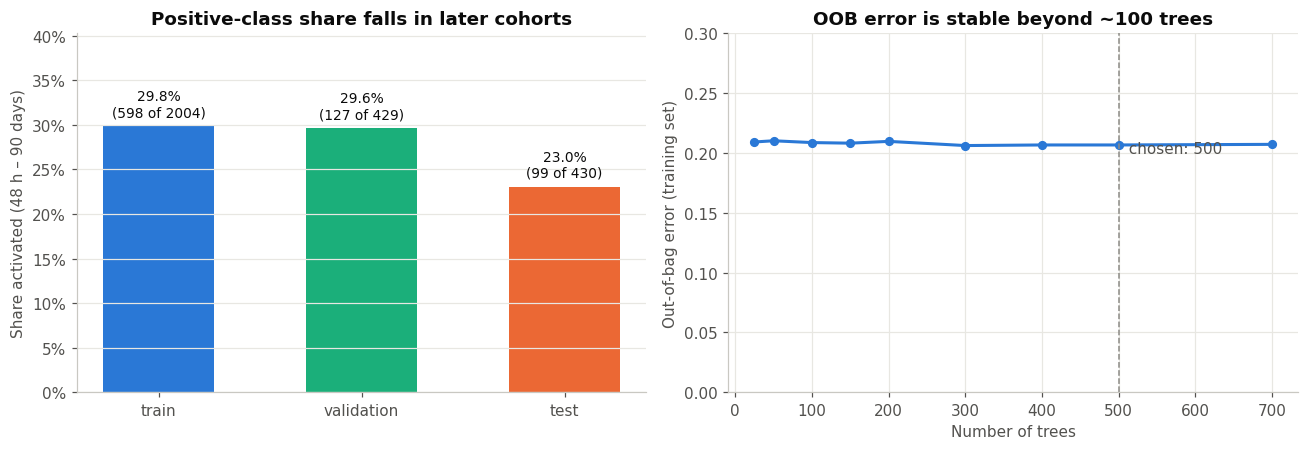

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
subsets = ["train", "validation", "test"]; colours = [C_TRAIN, C_VAL, C_TEST]
rates = [truth[s].mean() for s in subsets]
bars = ax.bar(subsets, rates, color=colours, width=0.55)
for b, s, r in zip(bars, subsets, rates):
    ax.text(b.get_x() + b.get_width() / 2, r + 0.008, f"{r:.1%}\n({truth[s].sum()} of {len(truth[s])})",
            ha="center", va="bottom", color=C_INK, fontsize=9)
ax.set_ylim(0, max(rates) * 1.35); ax.set_ylabel("Share activated (48 h – 90 days)")
ax.set_title("Positive-class share falls in later cohorts"); ax.grid(axis="x", visible=False)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))

ax = axes[1]
ax.plot(tree_grid, oob_curve, color=C_TRAIN, marker="o", markersize=5)
ax.axvline(N_TREES, color=C_GREY, linestyle="--", linewidth=1)
ax.text(N_TREES, max(oob_curve), f"  chosen: {N_TREES}", color=C_MUTED, va="top")
ax.set_xlabel("Number of trees"); ax.set_ylabel("Out-of-bag error (training set)")
ax.set_ylim(0, 0.3); ax.set_title("OOB error is stable beyond ~100 trees")
fig.tight_layout(); save(fig, "01_class_balance_and_oob"); plt.show()

### 5.2 Training: hyperparameter search (validation ROC AUC) and overfitting gap

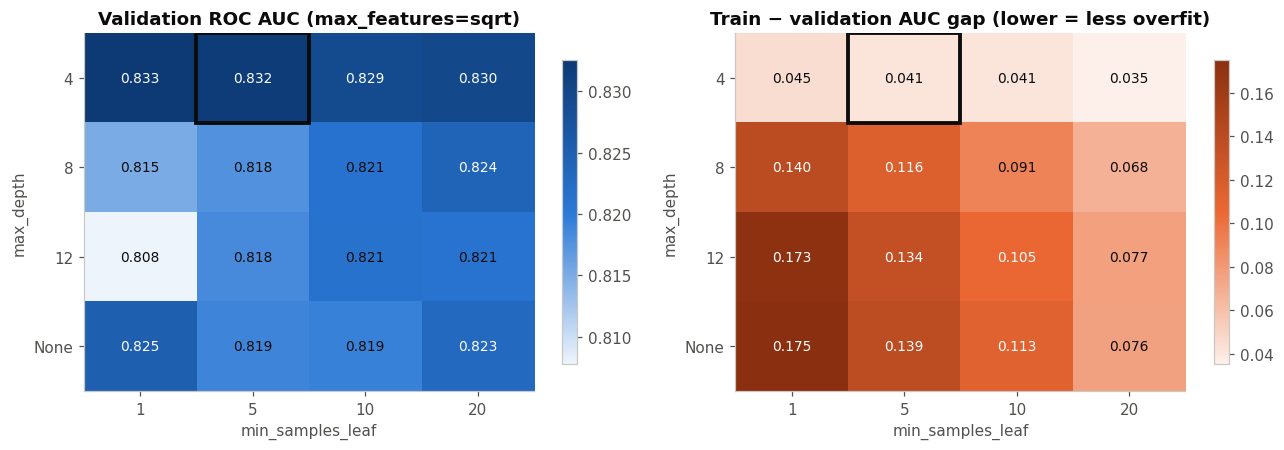

In [27]:
best_mf = BEST_PARAMS["max_features"]
sub = tuning[tuning["max_features"].astype(str) == str(best_mf)]
heat = sub.pivot(index="max_depth", columns="min_samples_leaf", values="val_auc").reindex([4, 8, 12, "None"])
gap = sub.pivot(index="max_depth", columns="min_samples_leaf", values="gap").reindex([4, 8, 12, "None"])
blues = LinearSegmentedColormap.from_list("b", ["#eef4fc", "#2a78d6", "#0d3a75"])
oranges = LinearSegmentedColormap.from_list("o", ["#fdf0ea", "#eb6834", "#8a3010"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, data, cmap, title, fmt in [
        (axes[0], heat, blues, f"Validation ROC AUC (max_features={best_mf})", "{:.3f}"),
        (axes[1], gap, oranges, "Train − validation AUC gap (lower = less overfit)", "{:.3f}")]:
    im = ax.imshow(data.values.astype(float), cmap=cmap, aspect="auto")
    ax.set_xticks(range(data.shape[1]), data.columns); ax.set_yticks(range(data.shape[0]), data.index)
    ax.set_xlabel("min_samples_leaf"); ax.set_ylabel("max_depth"); ax.set_title(title); ax.grid(False)
    vals = data.values.astype(float); mid = np.nanmean(vals)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, fmt.format(vals[i, j]), ha="center", va="center", fontsize=9,
                    color="white" if vals[i, j] > mid else C_INK)
    fig.colorbar(im, ax=ax, shrink=0.85)
bi = list(heat.index).index("None" if BEST_PARAMS["max_depth"] is None else BEST_PARAMS["max_depth"])
bj = list(heat.columns).index(BEST_PARAMS["min_samples_leaf"])
for ax in axes:
    ax.add_patch(plt.Rectangle((bj - 0.5, bi - 0.5), 1, 1, fill=False, edgecolor=C_INK, linewidth=2.5))
fig.tight_layout(); save(fig, "02_hyperparameter_search"); plt.show()

### 5.3 Training vs validation vs unseen test: headline metrics

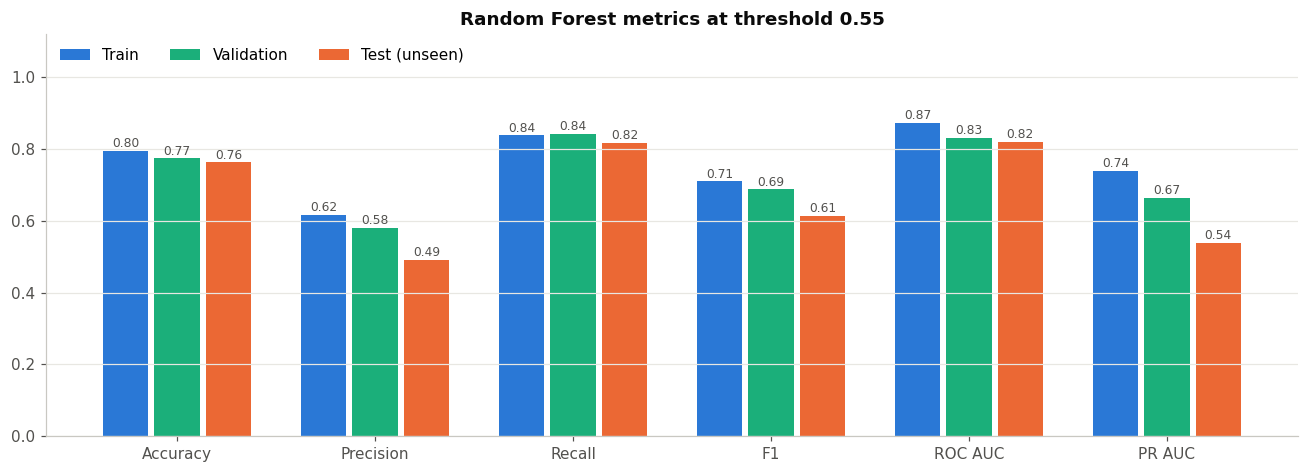

In [28]:
metric_names = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]
labels = ["Accuracy", "Precision", "Recall", "F1", "ROC AUC", "PR AUC"]
x = np.arange(len(metric_names)); w = 0.26
fig, ax = plt.subplots(figsize=(12, 4.4))
for k, (s, c) in enumerate(zip(subsets, colours)):
    vals = rf_metrics.loc[s, metric_names].values
    bars = ax.bar(x + (k - 1) * w, vals, w - 0.03, color=c, label=s.capitalize() + (" (unseen)" if s == "test" else ""))
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", fontsize=8, color=C_MUTED)
ax.set_xticks(x, labels); ax.set_ylim(0, 1.12); ax.grid(axis="x", visible=False)
ax.set_title(f"Random Forest metrics at threshold {THRESHOLD:.2f}"); ax.legend(ncol=3, loc="upper left")
fig.tight_layout(); save(fig, "03_metrics_train_val_test"); plt.show()

### 5.4 Unseen test: ROC and precision–recall curves (with train and validation for reference)

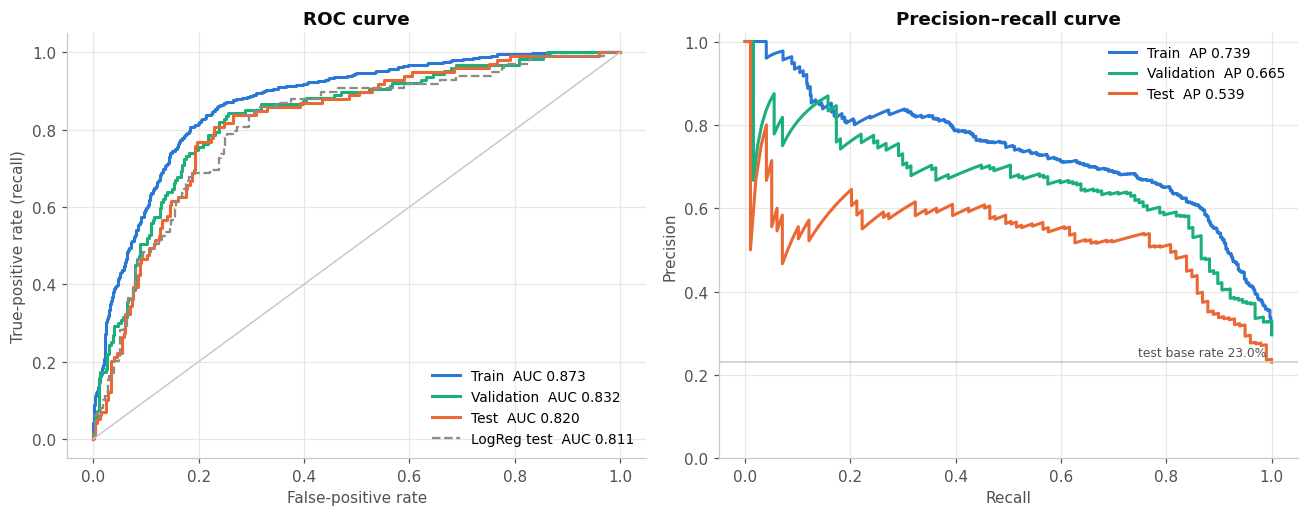

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for s, c in zip(subsets, colours):
    fpr, tpr, _ = roc_curve(truth[s], proba[s])
    axes[0].plot(fpr, tpr, color=c, label=f"{s.capitalize()}  AUC {roc_auc_score(truth[s], proba[s]):.3f}")
    pr, rc, _ = precision_recall_curve(truth[s], proba[s])
    axes[1].plot(rc, pr, color=c, label=f"{s.capitalize()}  AP {average_precision_score(truth[s], proba[s]):.3f}")
fpr, tpr, _ = roc_curve(y_test, lr_proba["test"])
axes[0].plot(fpr, tpr, color=C_GREY, linestyle="--", linewidth=1.5,
             label=f"LogReg test  AUC {roc_auc_score(y_test, lr_proba['test']):.3f}")
axes[0].plot([0, 1], [0, 1], color="#c9c8c2", linewidth=1)
axes[1].axhline(y_test.mean(), color="#c9c8c2", linewidth=1)
axes[1].text(0.99, y_test.mean() + 0.015, f"test base rate {y_test.mean():.1%}", ha="right", color=C_MUTED, fontsize=8)
axes[0].set(xlabel="False-positive rate", ylabel="True-positive rate (recall)", title="ROC curve")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision–recall curve", ylim=(0, 1.02))
for ax in axes: ax.legend(loc="lower right" if ax is axes[0] else "upper right", fontsize=9)
fig.tight_layout(); save(fig, "04_roc_pr_curves"); plt.show()

### 5.5 Confusion matrices: training vs unseen test

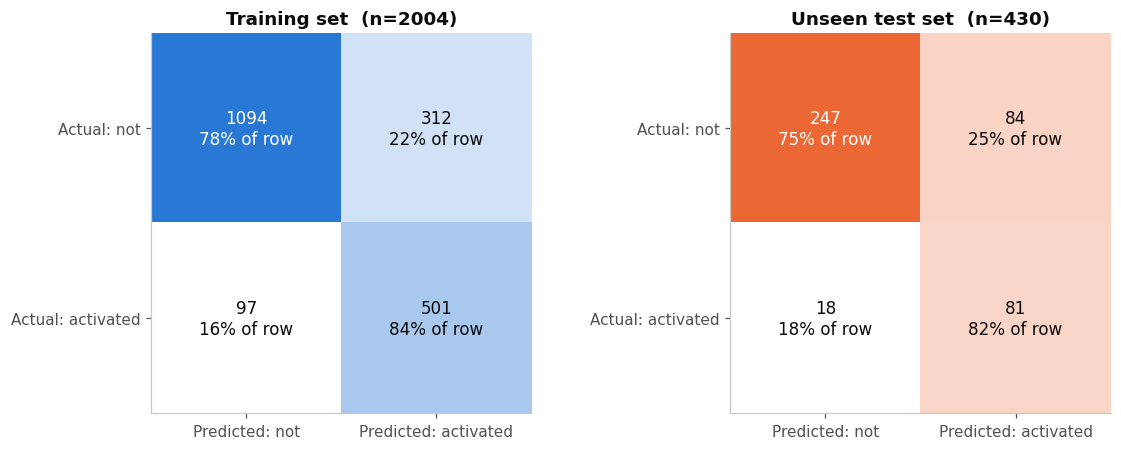

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, s, c in [(axes[0], "train", C_TRAIN), (axes[1], "test", C_TEST)]:
    cm = confusion_matrix(truth[s], (proba[s] >= THRESHOLD).astype(int))
    cmap = LinearSegmentedColormap.from_list(s, ["#ffffff", c])
    ax.imshow(cm, cmap=cmap); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n{cm[i, j] / cm[i].sum():.0%} of row", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else C_INK, fontsize=11)
    ax.set_xticks([0, 1], ["Predicted: not", "Predicted: activated"])
    ax.set_yticks([0, 1], ["Actual: not", "Actual: activated"])
    ax.set_title(("Training set" if s == "train" else "Unseen test set") + f"  (n={cm.sum()})")
fig.tight_layout(); save(fig, "05_confusion_matrices"); plt.show()

### 5.6 Unseen test: what drives the predictions

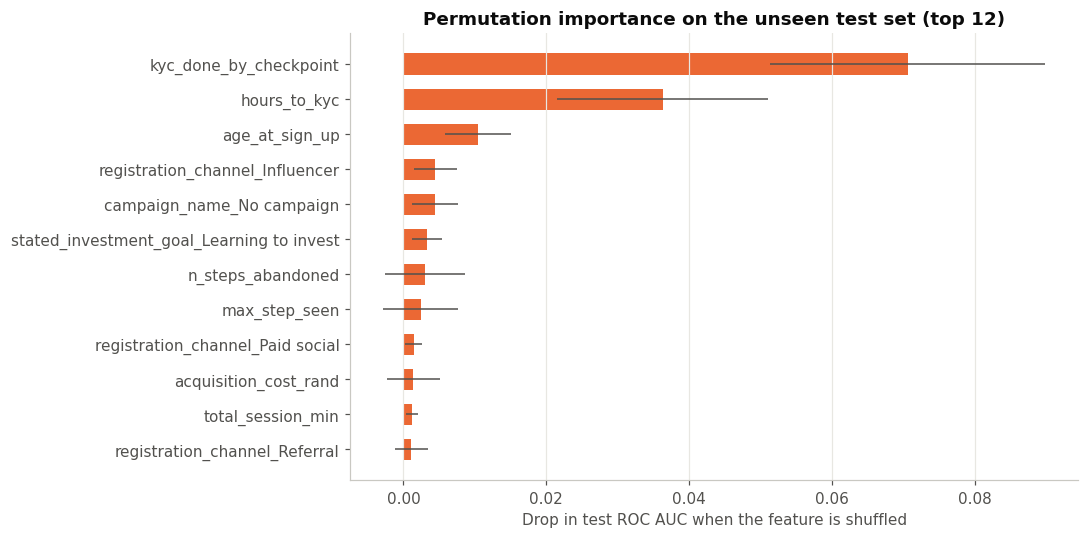

In [31]:
top = importance.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top["feature"], top["perm_importance"], xerr=top["perm_std"], color=C_TEST, height=0.6,
        error_kw={"ecolor": C_MUTED, "elinewidth": 1})
ax.set_xlabel("Drop in test ROC AUC when the feature is shuffled")
ax.set_title("Permutation importance on the unseen test set (top 12)"); ax.grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "06_feature_importance"); plt.show()

### 5.7 Unseen test: activation rate by score decile, and probability calibration

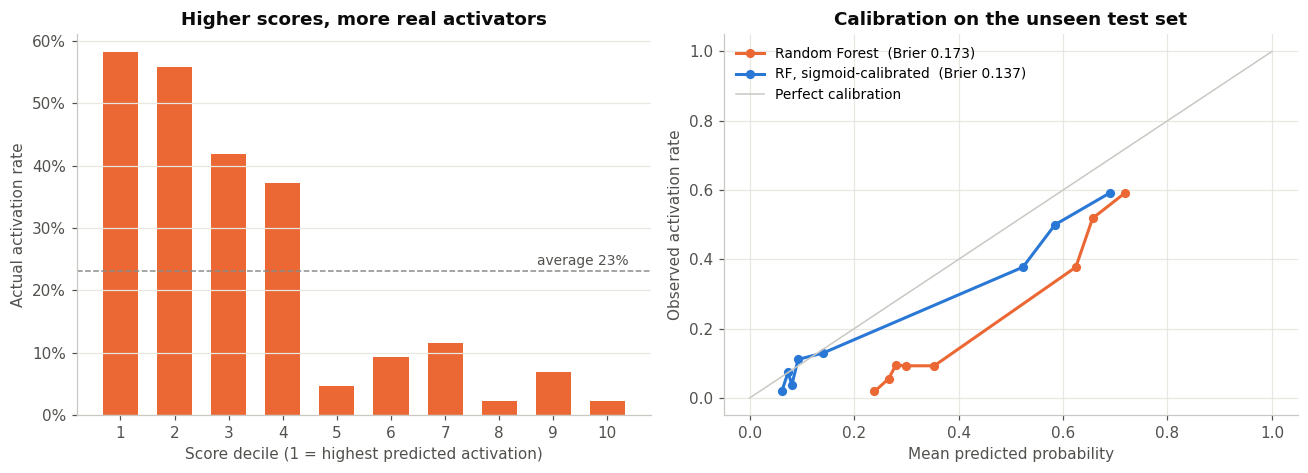

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
ax = axes[0]
ax.bar(lift.index.astype(str), lift["activation_rate"], color=C_TEST, width=0.65)
ax.axhline(y_test.mean(), color=C_GREY, linestyle="--", linewidth=1)
ax.text(9.4, y_test.mean() + 0.01, f"average {y_test.mean():.0%}", ha="right", color=C_MUTED, fontsize=9)
ax.set_xlabel("Score decile (1 = highest predicted activation)"); ax.set_ylabel("Actual activation rate")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Higher scores, more real activators"); ax.grid(axis="x", visible=False)

ax = axes[1]
for p, c, lab in [(proba["test"], C_TEST, "Random Forest"), (cal_proba["test"], C_TRAIN, "RF, sigmoid-calibrated")]:
    frac, mean_p = calibration_curve(y_test, p, n_bins=8, strategy="quantile")
    ax.plot(mean_p, frac, marker="o", markersize=5, color=c, label=f"{lab}  (Brier {brier_score_loss(y_test, p):.3f})")
ax.plot([0, 1], [0, 1], color="#c9c8c2", linewidth=1, label="Perfect calibration")
ax.set(xlabel="Mean predicted probability", ylabel="Observed activation rate", title="Calibration on the unseen test set")
ax.legend(fontsize=9, loc="upper left")
fig.tight_layout(); save(fig, "07_lift_and_calibration"); plt.show()

### 5.8 Unseen test: Random Forest against the baselines

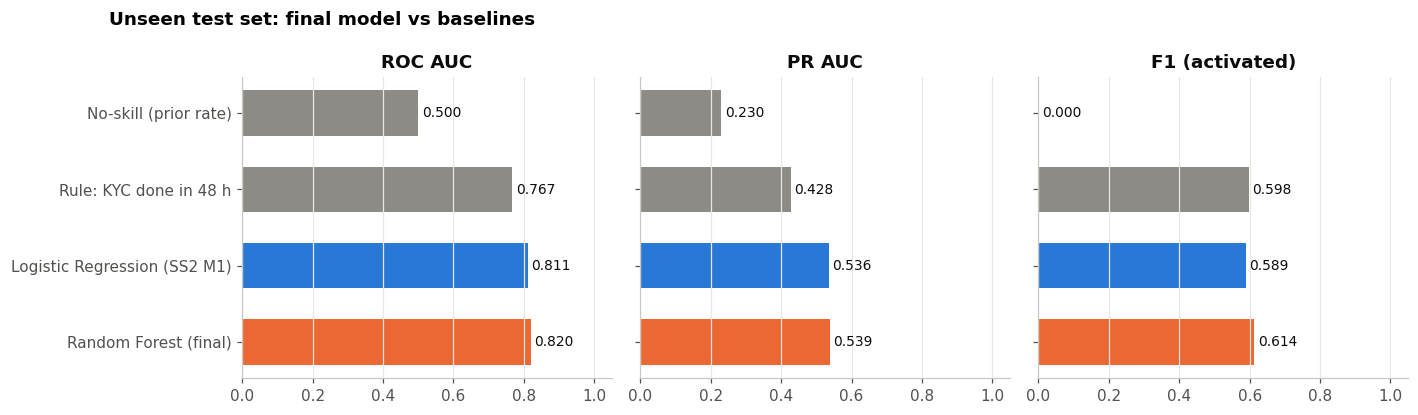

In [33]:
order = ["No-skill (prior rate)", "Rule: KYC done in 48 h", "Logistic Regression (SS2 M1)", "Random Forest (final)"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, metric, title in zip(axes, ["roc_auc", "pr_auc", "f1"], ["ROC AUC", "PR AUC", "F1 (activated)"]):
    vals = comparison.loc[order, metric]
    cols = [C_GREY, C_GREY, C_TRAIN, C_TEST]
    ax.barh(order, vals, color=cols, height=0.6)
    for i, v in enumerate(vals):
        ax.text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=9, color=C_INK)
    ax.set_xlim(0, 1.05); ax.set_title(title); ax.grid(axis="y", visible=False)
axes[0].invert_yaxis()
fig.suptitle("Unseen test set: final model vs baselines", fontweight="bold", x=0.08, ha="left")
fig.tight_layout(); save(fig, "08_model_vs_baselines"); plt.show()

### 5.9 Summary of the visual results

- **5.1** Training, validation and test hold 29.8%, 29.6% and 23.0% positives: drift towards lower activation in recent cohorts. The OOB error is flat from about 100 trees, which supports 500 trees.
- **5.2** Shallow trees (depth 4) give the best validation AUC *and* the smallest overfitting gap. Deeper trees fit training data much more closely without validating better.
- **5.3** Train → validation → test metrics fall only gently, except precision and PR AUC, which track the lower test base rate.
- **5.4** Train, validation and test ROC curves lie close together, with the Logistic Regression benchmark just below on test. The test PR curve stays well above the 23% base rate across most recall levels.
- **5.5** Recall for activators is similar on train (84%) and test (82%). Most test errors are false positives (84 accounts nudged that would not have funded), which is the cheaper error for a nudge campaign.
- **5.6** KYC within 48 h is the dominant signal on unseen data.
- **5.7** Activation rate falls steeply across score deciles, so the score can rank who to nudge first. Calibration moves predicted probabilities onto the diagonal.
- **5.8** The final Random Forest leads all baselines on ROC AUC and F1 on the unseen test set; PR AUC is level with Logistic Regression.

---
**Outputs written by this notebook:** `Data/processed/ss3_model_table.csv` · `models/ss3_random_forest.pkl` · `results/metrics/ss3_random_forest_metrics.json` · `results/metrics/ss3_rf_tuning_grid.csv` · `results/metrics/ss3_feature_importances.csv` · `results/reports/ss3_test_comparison.csv` · `results/reports/ss3_figures/*.png`